# Parte II: algoritmos da disciplina

Aplicação dos algoritmos pedidos no documento e vistos na disciplina. Usamos a maior componente conexa do grafo, com **21.284 produtos e 320.742 arestas**. Como a base inclui jogos, consoles e acessórios, chamamos os vértices de produtos.

Implementamos BFS, DFS, a verificação de Euler, Tarjan, Dijkstra, Bellman-Ford, Floyd-Warshall, Prim e Kruskal. Usamos o NetworkX como referência nas comparações descritas a seguir.

Para os caminhos mínimos e as árvores geradoras, usamos a distância $d = 1/w$, em que $w$ é a quantidade de usuários que avaliaram os dois produtos. Assim, quanto mais avaliadores em comum, menor é a distância. Todos esses valores são positivos.

Para medir os tempos:

- fazemos duas execuções de aquecimento, que não entram nas medidas;
- medimos 30 repetições de cada algoritmo com um relógio de alta precisão;
- solicitamos a coleta de objetos que não estão mais em uso antes de cada repetição, para reduzir sua interferência na medida;
- calculamos a média, o desvio padrão amostral e o intervalo de confiança de 95%;
- usamos o mesmo vértice de origem em BFS, DFS, Dijkstra e Prim: o produto de maior grau.

Com 30 repetições, usamos a aproximação normal para o intervalo de confiança:

$$IC_{95\%} = \bar{x} \pm 1{,}96\frac{s}{\sqrt{30}}$$

Nessa expressão, $\bar{x}$ é a média dos tempos e $s$ é o desvio padrão amostral. Manter a origem fixa permite comparar as repetições sem mudar o ponto de partida. Os tempos ainda podem variar por causa das condições de execução do computador.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

from IPython.display import Markdown, display

from src.comum import config
from src.parte2.arvore_geradora import calcular_kruskal, calcular_prim
from src.parte2.buscas import diagnosticar_euler, encontrar_pontes_e_articulacoes, visitar_em_profundidade
from src.parte2.caminhos_minimos import calcular_bellman_ford, calcular_dijkstra, calcular_floyd_warshall
from src.comum.carga import carregar_grafo_analise
from src.parte2.desempenho import (
    ajustar_inclinacao, custo_heap, custo_linear, descrever_ambiente, induzir_bola_de_neve,
    medir_escalabilidade,
)
from src.comum.exportacao import escrever_tabela, formatar_markdown
from src.comum.grafo import distancias_em_largura, montar_adjacencia_ponderada
from src.comum.validacao import calcular_referencia
from src.comum.visualizacao import plotar_escalabilidade, salvar_figura

DIR_RESULTADOS, DIR_IMAGENS = config.RAIZ / "results", config.RAIZ / "imagens"
grafo = carregar_grafo_analise(config.DIR_PROCESSADO)
adjacencia, distancias = grafo.adjacencia, montar_adjacencia_ponderada(grafo.pesos)
n, m = len(adjacencia), len(grafo.pesos)
hub = max(adjacencia, key=lambda v: len(adjacencia[v]))
print(f"LCC: n = {n:,}  m = {m:,}  |  origem fixa: {grafo.jogos[hub].titulo} (grau {len(adjacencia[hub])})")
display(Markdown(formatar_markdown(["item", "valor"], descrever_ambiente().items())))

LCC: n = 21,284  m = 320,742  |  origem fixa: Xbox 360 Wireless Controller - Glossy Black (grau 1274)


| item | valor |
|---|---|
| cpu | Intel(R) Core(TM) 7 150U |
| nucleos | 12 |
| ram_gb | 30.3 |
| sistema | Linux-7.0.0-43-generic-x86_64-with-glibc2.43 |
| python | 3.11.15 |
| networkx | 3.6.1 |
| igraph | 1.0.0 |
| numpy | 2.4.6 |

## 1. Conferência dos resultados

Verificamos os resultados de cada algoritmo com os seguintes critérios:

- **BFS e DFS:** verificamos se alcançam todos os vértices da maior componente.
- **Dijkstra:** comparamos as distâncias com as do NetworkX, aceitando diferenças menores que $10^{-9}$.
- **Prim e Kruskal:** comparamos o custo total da árvore com o resultado do NetworkX, aceitando diferenças menores que $10^{-6}$. Com pesos iguais, os algoritmos podem escolher arestas diferentes e ainda obter o mesmo custo mínimo.
- **Tarjan:** comparamos os conjuntos de pontes e de vértices de articulação com os do NetworkX.
- **Euler:** comparamos a resposta sobre a existência de um circuito euleriano com a do NetworkX.

Também comparamos Bellman-Ford com nossa implementação de Dijkstra em um subgrafo de **2.000 vértices**. Para Floyd-Warshall, usamos um subgrafo de **400 vértices** e comparamos as distâncias com as obtidas por Dijkstra a partir de todas as origens. Nessas comparações, a tolerância é de $10^{-9}$.

In [2]:
ordem_bfs = distancias_em_largura(adjacencia, hub)
ordem_dfs = visitar_em_profundidade(adjacencia, hub)
euler = diagnosticar_euler(adjacencia)
tarjan = encontrar_pontes_e_articulacoes(adjacencia)
dijkstra = calcular_dijkstra(distancias, hub)
kruskal, prim = calcular_kruskal(distancias), calcular_prim(distancias, hub)
referencia = calcular_referencia(distancias, hub)

sub_bf = induzir_bola_de_neve(grafo.pesos, adjacencia, hub, 2000)
bellman = calcular_bellman_ford(sub_bf.adjacencia_ponderada, hub)
dijkstra_sub = calcular_dijkstra(sub_bf.adjacencia_ponderada, hub)
sub_fw = induzir_bola_de_neve(grafo.pesos, adjacencia, hub, 400)
floyd = calcular_floyd_warshall(sub_fw.adjacencia_ponderada)
indice = {v: i for i, v in enumerate(floyd.vertices)}
floyd_ok = all(abs(floyd.distancias[indice[o], indice[v]] - d) < 1e-9
               for o in sub_fw.adjacencia for v, d in calcular_dijkstra(sub_fw.adjacencia_ponderada, o).items())

validacao = [
    ["BFS", "alcança todos os n vértices", len(ordem_bfs) == n],
    ["DFS", "alcança todos os n vértices", len(ordem_dfs) == n],
    ["Euler", "mesmo veredito do nx.is_eulerian", euler.tem_circuito == referencia.euleriano],
    ["Tarjan (pontes)", "conjunto igual ao nx.bridges", tarjan.pontes == referencia.pontes],
    ["Tarjan (articulações)", "conjunto igual ao nx.articulation_points", tarjan.articulacoes == referencia.articulacoes],
    ["Dijkstra", "distâncias iguais (tol. 1e-9)", max(abs(dijkstra[v] - referencia.distancias_dijkstra[v]) for v in adjacencia) < 1e-9],
    ["Bellman-Ford (n=2000)", "igual ao Dijkstra próprio", max(abs(bellman[v] - dijkstra_sub[v]) for v in sub_bf.adjacencia) < 1e-9],
    ["Floyd-Warshall (n=400)", "igual ao Dijkstra de todas as origens", floyd_ok],
    ["Kruskal", "custo igual ao nx.minimum_spanning_tree", abs(kruskal.custo_total - referencia.custo_arvore_geradora) < 1e-6],
    ["Prim", "custo igual ao nx.minimum_spanning_tree", abs(prim.custo_total - referencia.custo_arvore_geradora) < 1e-6],
]
display(Markdown(formatar_markdown(["algoritmo", "critério", "ok?"], validacao)))
assert all(ok for *_, ok in validacao)

| algoritmo | critério | ok? |
|---|---|---|
| BFS | alcança todos os n vértices | True |
| DFS | alcança todos os n vértices | True |
| Euler | mesmo veredito do nx.is_eulerian | True |
| Tarjan (pontes) | conjunto igual ao nx.bridges | True |
| Tarjan (articulações) | conjunto igual ao nx.articulation_points | True |
| Dijkstra | distâncias iguais (tol. 1e-9) | True |
| Bellman-Ford (n=2000) | igual ao Dijkstra próprio | True |
| Floyd-Warshall (n=400) | igual ao Dijkstra de todas as origens | True |
| Kruskal | custo igual ao nx.minimum_spanning_tree | True |
| Prim | custo igual ao nx.minimum_spanning_tree | True |

Os **dez critérios verificados passaram**. Isso mostra que os resultados foram compatíveis nas entradas testadas, dentro das tolerâncias usadas.

Em Tarjan, conferimos quais arestas são pontes e quais vértices são articulações, e não apenas suas quantidades. Para BFS e DFS, a verificação foi mais simples: ambas as buscas alcançaram todos os vértices. Esse teste não compara a ordem das visitas nem todas as distâncias da BFS com uma referência.

Nas árvores geradoras, comparamos o custo total porque pode existir mais de uma árvore mínima. Bellman-Ford e Floyd-Warshall foram conferidos apenas nos subgrafos indicados acima.

Como usamos distâncias positivas, Dijkstra atende ao problema de caminhos mínimos a partir de uma origem. Bellman-Ford também funciona, mas sua capacidade de lidar com pesos negativos não é necessária neste grafo.

## 2. O que os algoritmos mostram sobre o grafo

A seguir, analisamos a existência de caminhos e circuitos eulerianos, as ligações importantes para manter o grafo conectado e as árvores geradoras mínimas.

In [3]:
print(f"Euler: conexo={euler.conexo}  vértices de grau ímpar={euler.vertices_grau_impar:,}  "
      f"circuito={euler.tem_circuito}  caminho={euler.tem_caminho}")

folhas = {v for v, viz in adjacencia.items() if len(viz) == 1}
pontes_internas = {(p, q) for p, q in tarjan.pontes if p not in folhas and q not in folhas}
print(f"Tarjan: {len(tarjan.pontes):,} pontes ({len(tarjan.pontes) - len(pontes_internas):,} levam a folhas, "
      f"{len(pontes_internas):,} internas)  |  {len(tarjan.articulacoes):,} articulações")
top_articulacoes = sorted(tarjan.articulacoes, key=lambda v: len(adjacencia[v]), reverse=True)[:8]
display(Markdown(formatar_markdown(["articulação de maior grau", "plataforma", "grau"],
    [[grafo.jogos[v].titulo[:50], grafo.jogos[v].plataforma, len(adjacencia[v])] for v in top_articulacoes])))

pesos_arvore = sorted(((grafo.pesos[a], a) for a in kruskal.arestas), reverse=True)
fracao_w2 = sum(1 for w, _ in pesos_arvore if w == 2) / len(pesos_arvore)
print(f"MST: {len(kruskal.arestas):,} arestas (= n - 1)  custo = {kruskal.custo_total:.2f}  "
      f"arestas com w = 2: {fracao_w2:.1%}")
display(Markdown(formatar_markdown(["jogo A", "jogo B", "w"],
    [[grafo.jogos[p].titulo[:40], grafo.jogos[q].titulo[:40], w] for w, (p, q) in pesos_arvore[:10]])))

Euler: conexo=True  vértices de grau ímpar=11,996  circuito=False  caminho=False
Tarjan: 4,248 pontes (3,951 levam a folhas, 297 internas)  |  3,032 articulações


| articulação de maior grau | plataforma | grau |
|---|---|---|
| Xbox 360 Wireless Controller - Glossy Black | Xbox 360 | 1274 |
| Wii | Wii | 1210 |
| The Last of Us Remastered - PlayStation 4 | PlayStation 4 | 1172 |
| Diablo III | PC | 1159 |
| Halo 4 - Xbox 360 (Standard Game) | Xbox 360 | 1098 |
| Assassin's Creed | Xbox 360 | 1090 |
| Uncharted 4: A Thief's End - PlayStation 4 | PlayStation 4 | 1084 |
| Xbox 360 LIVE 1600 Points | Xbox One | 1070 |

MST: 21,283 arestas (= n - 1)  custo = 6876.12  arestas com w = 2: 40.2%


| jogo A | jogo B | w |
|---|---|---|
| Razer DeathAdder Chroma - Multi-Color Er | Razer DeathAdder Chroma - Multi-Color Er | 2786 |
| Razer DeathAdder Expert - Optical Esport | Razer DeathAdder Chroma - Multi-Color Er | 2126 |
| SimCity: Limited Edition | SimCity [Instant Access] | 1975 |
| Turtle Beach - Ear Force PX22 Universal  | Turtle Beach - Ear Force PX22  - Univers | 1350 |
| Razer Naga Left-Handed - Ergonomic MMO G | Razer Naga Epic Chroma MMO Gaming Mouse  | 845 |
| SADES Spirit Wolf 7.1 Surround Stereo So | SADES Spirit Wolf 7.1 Surround Stereo So | 745 |
| Sentey Mouse Group | Sentey Mouse Group | 505 |
| SADES SA-708 Stereo Gaming Headset with  | SADES SA708 3.5mm Stereo Gaming Headset  | 455 |
| SADES SA-708 Stereo Gaming Headset with  | SADES SA708 3.5mm Stereo Gaming Headset  | 392 |
| Pokémon Moon - Nintendo 3DS | Pokémon Sun - Nintendo 3DS | 350 |

**Euler.** O grafo é conexo, mas tem **11.996 vértices de grau ímpar**, cerca de 56% do total. Para existir um circuito euleriano, todos os graus precisam ser pares. Para existir um caminho euleriano aberto, precisam existir exatamente dois vértices de grau ímpar. Portanto, o grafo não possui nenhum dos dois. Não é possível percorrer todas as arestas exatamente uma vez em um único percurso.

**Tarjan.** Encontramos **4.248 pontes**. Uma ponte é uma aresta cuja remoção aumenta o número de componentes. Dessas pontes, **3.951**, cerca de 93%, estão ligadas a folhas, que são vértices de grau 1. Ao remover uma dessas arestas, o produto da ponta fica isolado. As outras **297 pontes** não têm folhas nas extremidades.

Também encontramos **3.032 vértices de articulação**. Remover qualquer um deles, junto com suas arestas, separa o grafo em mais componentes. Entre os de maior grau estão o controle do Xbox 360, Wii, The Last of Us e Diablo III. Isso mostra que esses produtos têm importância para manter a rede conectada. Porém, a contagem de articulações não informa, sozinha, o tamanho da perda causada pela remoção de cada produto. Esse impacto será analisado nos testes de robustez.

**Árvore geradora mínima.** A árvore obtida tem **21.283 arestas**, exatamente $n-1$, e custo total de **6.876,12**, usando $d = 1/w$. Ela conecta todos os vértices sem formar ciclos. Como valores maiores de $w$ dão distâncias menores, a escolha favorece ligações com mais avaliadores em comum.

Mesmo assim, **40,2% das arestas da árvore têm peso $w = 2$**. Portanto, a árvore também depende de ligações com o mínimo de avaliadores em comum permitido no grafo.

Entre as ligações de maior peso aparecem produtos com títulos muito parecidos, como modelos de mouse e de headset, além de edições de SimCity e do par Pokémon Sun/Moon. Os títulos sugerem relações entre versões ou produtos próximos, mas não são suficientes para confirmar que se trata do mesmo item em anúncios diferentes.

## 3. Tempos de execução e crescimento do custo

Para observar como o tempo muda com o tamanho do grafo, usamos recortes com **1.000, 2.000, 4.000 e 8.000 vértices**, além da maior componente completa. Selecionamos os primeiros vértices visitados por uma BFS a partir do produto de maior grau e mantemos as arestas entre eles. Esse método, chamado de bola de neve, mantém os recortes conectados.

Para Bellman-Ford, usamos recortes de **500, 1.000, 2.000 e 4.000 vértices**. Para Floyd-Warshall, usamos **100, 200, 400 e 800 vértices**, devido ao custo maior de calcular caminhos entre todos os pares.

Em cada tamanho, medimos 30 repetições. Depois, comparamos o tempo médio com a expressão de custo teórico de cada algoritmo. Ajustamos uma reta usando o logaritmo dos tempos e dos custos. Uma inclinação próxima de 1 indica que o tempo cresceu de forma parecida com essa expressão nos tamanhos testados. Isso ajuda na comparação, mas não prova a complexidade do algoritmo.

Os recortes partem sempre do mesmo produto de maior grau. Por isso, os resultados descrevem esse conjunto de entradas e não representam todos os grafos possíveis.

In [4]:
tamanhos = [1000, 2000, 4000, 8000, n]
subgrafos = [induzir_bola_de_neve(grafo.pesos, adjacencia, hub, t) for t in tamanhos]
lineares = {
    "BFS": lambda s: distancias_em_largura(s.adjacencia, s.origem),
    "DFS": lambda s: visitar_em_profundidade(s.adjacencia, s.origem),
    "Euler": lambda s: diagnosticar_euler(s.adjacencia),
    "Tarjan": lambda s: encontrar_pontes_e_articulacoes(s.adjacencia),
}
com_heap = {
    "Dijkstra": lambda s: calcular_dijkstra(s.adjacencia_ponderada, s.origem),
    "Prim": lambda s: calcular_prim(s.adjacencia_ponderada, s.origem),
    "Kruskal": lambda s: calcular_kruskal(s.adjacencia_ponderada),
}
pontos = medir_escalabilidade(subgrafos, lineares | com_heap)

sub_bellman = [induzir_bola_de_neve(grafo.pesos, adjacencia, hub, t) for t in (500, 1000, 2000, 4000)]
pontos += medir_escalabilidade(sub_bellman, {"Bellman-Ford": lambda s: calcular_bellman_ford(s.adjacencia_ponderada, s.origem)})
sub_floyd = [induzir_bola_de_neve(grafo.pesos, adjacencia, hub, t) for t in (100, 200, 400, 800)]
pontos += medir_escalabilidade(sub_floyd, {"Floyd-Warshall": lambda s: calcular_floyd_warshall(s.adjacencia_ponderada)})
print("subgrafos (n, m):", [(s.n, s.m) for s in subgrafos])

subgrafos (n, m): [(1000, 35725), (2000, 76324), (4000, 136261), (8000, 242799), (21284, 320742)]


In [5]:
complexidades = {
    "BFS": ("O(n + m)", custo_linear), "DFS": ("O(n + m)", custo_linear),
    "Euler": ("O(n + m)", custo_linear), "Tarjan": ("O(n + m)", custo_linear),
    "Dijkstra": ("O(m log n)", custo_heap), "Prim": ("O(m log n)", custo_heap),
    "Kruskal": ("O(m log n)", custo_heap),
    "Bellman-Ford": ("O(n·m)", lambda n_, m_: n_ * m_),
    "Floyd-Warshall": ("O(n³)", lambda n_, m_: n_ ** 3),
}
resumo, series = [], {}
for nome, (rotulo, custo) in complexidades.items():
    meus = [p for p in pontos if p.algoritmo == nome]
    inclinacao = ajustar_inclinacao([custo(p.n, p.m) for p in meus], [p.tempo.media for p in meus])
    series[nome] = [(custo(p.n, p.m), p.tempo.media, p.tempo.media - p.tempo.ic_inferior) for p in meus]
    maior = meus[-1]
    resumo.append([nome, rotulo, maior.n, maior.m, f"{maior.tempo.media:.4f}", f"{maior.tempo.desvio_padrao:.4f}",
                   f"[{maior.tempo.ic_inferior:.4f}, {maior.tempo.ic_superior:.4f}]", f"{inclinacao:.2f}"])
floyd_pontos = [p for p in pontos if p.algoritmo == "Floyd-Warshall"]
inclinacao_floyd_n = ajustar_inclinacao([p.n for p in floyd_pontos], [p.tempo.media for p in floyd_pontos])
cabecalho = ["algoritmo", "complexidade", "n", "m", "média (s)", "DP (s)", "IC 95% (s)", "inclinação"]
display(Markdown(formatar_markdown(cabecalho, resumo)))
print(f"Floyd-Warshall: inclinação de log t contra log n = {inclinacao_floyd_n:.2f} (teórico: 3)")

with open(DIR_RESULTADOS / "parte2_resumo.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(cabecalho, resumo, fluxo)
with open(DIR_RESULTADOS / "parte2_tempos.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(["algoritmo", "n", "m", "media", "dp", "ic_inf", "ic_sup", "repeticoes"],
                    ([p.algoritmo, p.n, p.m, p.tempo.media, p.tempo.desvio_padrao, p.tempo.ic_inferior,
                      p.tempo.ic_superior, p.tempo.n] for p in pontos), fluxo)

| algoritmo | complexidade | n | m | média (s) | DP (s) | IC 95% (s) | inclinação |
|---|---|---|---|---|---|---|---|
| BFS | O(n + m) | 21284 | 320742 | 0.0799 | 0.0238 | [0.0714, 0.0884] | 1.12 |
| DFS | O(n + m) | 21284 | 320742 | 0.1168 | 0.0313 | [0.1056, 0.1280] | 1.08 |
| Euler | O(n + m) | 21284 | 320742 | 0.1172 | 0.0148 | [0.1119, 0.1225] | 1.04 |
| Tarjan | O(n + m) | 21284 | 320742 | 0.2788 | 0.0229 | [0.2706, 0.2870] | 1.07 |
| Dijkstra | O(m log n) | 21284 | 320742 | 0.6212 | 0.0387 | [0.6074, 0.6350] | 1.04 |
| Prim | O(m log n) | 21284 | 320742 | 0.9167 | 0.1681 | [0.8565, 0.9768] | 1.16 |
| Kruskal | O(m log n) | 21284 | 320742 | 0.3941 | 0.0466 | [0.3775, 0.4108] | 0.92 |
| Bellman-Ford | O(n·m) | 4000 | 136261 | 0.3619 | 0.0271 | [0.3522, 0.3716] | 0.60 |
| Floyd-Warshall | O(n³) | 800 | 23209 | 0.8912 | 0.1143 | [0.8504, 0.9321] | 0.95 |

Floyd-Warshall: inclinação de log t contra log n = 2.86 (teórico: 3)


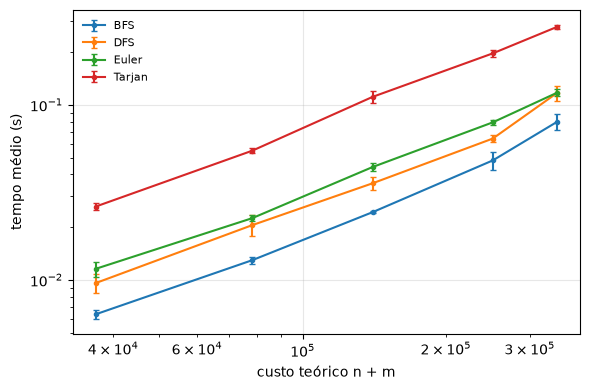

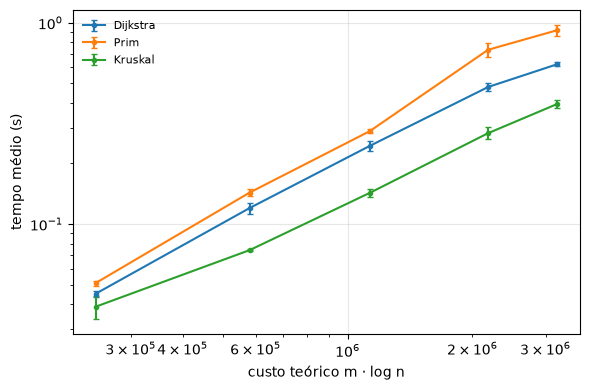

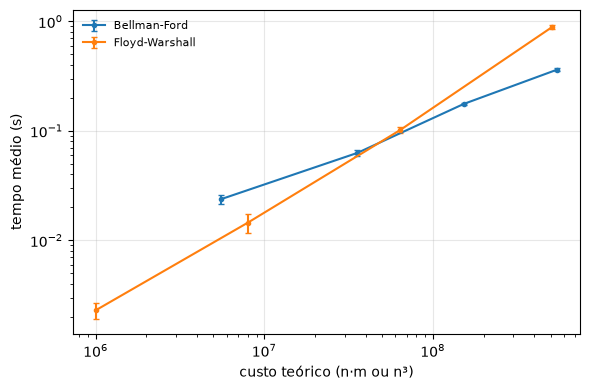

In [6]:
for familia, nomes, rotulo in (
    ("lineares", lineares, "custo teórico n + m"),
    ("heap", com_heap, "custo teórico m · log n"),
    ("bellman_floyd", ["Bellman-Ford", "Floyd-Warshall"], "custo teórico (n·m ou n³)"),
):
    figura = plotar_escalabilidade({k: series[k] for k in nomes}, rotulo)
    salvar_figura(figura, DIR_IMAGENS / f"parte2_escalabilidade_{familia}")

**BFS, DFS, Euler e Tarjan.** As inclinações ficaram entre **1,04 e 1,12** na comparação com $n+m$. Esse resultado é compatível com o crescimento linear esperado. Na maior componente, a BFS levou em média **0,0799 s**, enquanto Tarjan levou **0,2788 s**, cerca de 3,5 vezes mais. Ter a mesma ordem de complexidade não significa ter o mesmo tempo de execução.

**Dijkstra, Prim e Kruskal.** As inclinações ficaram entre **0,92 e 1,16** na comparação com $m\log n$. Na maior componente, Kruskal levou **0,3941 s**, Dijkstra levou **0,6212 s** e Prim levou **0,9167 s**. Entre os dois algoritmos de árvore geradora, Kruskal foi mais rápido neste experimento. Dijkstra resolve outro problema, então a comparação dos tempos não indica que um possa substituir o outro.

Prim também teve o maior desvio padrão entre esses algoritmos, de **0,1681 s**. As medidas mostram essa variação, mas não permitem atribuí-la a uma única causa.

**Bellman-Ford.** A inclinação foi **0,60** na comparação com $n\cdot m$, abaixo de 1. Isso indica que, nos recortes testados, o tempo cresceu menos do que essa expressão de pior caso. A possibilidade de encerrar o algoritmo quando as distâncias deixam de mudar ajuda a explicar esse comportamento, mas os tempos apresentados não mostram quantas rodadas foram feitas. O maior recorte usado aqui tem 4.000 vértices; por isso, seu tempo não deve ser comparado diretamente com os tempos dos algoritmos executados no grafo completo.

**Floyd-Warshall.** A inclinação foi **2,86** em relação a $n$ e **0,95** em relação a $n^3$. Esses valores ficaram próximos do crescimento cúbico esperado. No maior recorte, com 800 vértices, o tempo médio foi **0,8912 s**. Esse resultado também se refere a uma entrada menor que a dos demais algoritmos.

**Variação dos tempos.** Os intervalos de confiança mostram a incerteza da média nas 30 repetições. Essa incerteza varia entre os algoritmos. Por exemplo, a BFS teve intervalo de **0,0714 a 0,0884 s**, e Prim, de **0,8565 a 0,9768 s**. Portanto, não podemos afirmar que todos os tempos tiveram pouca variação ou que 30 repetições seriam suficientes em qualquer situação.

Os tempos foram medidos em um computador com **Intel Core 7 150U**, 12 núcleos reportados pelo ambiente, cerca de **30 GB de RAM** e **Python 3.11.15**. Os valores podem mudar em outro computador ou em outra execução.

## Resumo dos resultados

| Algoritmo | Resultado observado |
|---|---|
| BFS e DFS | Alcançaram os 21.284 vértices da maior componente. |
| Euler | Não há circuito nem caminho euleriano; o grafo tem 11.996 vértices de grau ímpar. |
| Tarjan | Encontrou 4.248 pontes, sendo 3.951 ligadas a folhas, e 3.032 vértices de articulação. |
| Dijkstra | As distâncias ficaram de acordo com as do NetworkX, dentro da tolerância usada. |
| Bellman-Ford e Floyd-Warshall | As distâncias ficaram de acordo com Dijkstra nos subgrafos testados. |
| Prim e Kruskal | Obtiveram árvores com o mesmo custo mínimo da referência, dentro da tolerância usada. |

Os testes de tempo mostraram um crescimento próximo das expressões teóricas para a maioria dos algoritmos. Bellman-Ford cresceu menos do que sua expressão de pior caso nas entradas usadas. Isso não muda sua complexidade teórica.

A análise também mostrou que muitas pontes estão ligadas a produtos com apenas um vizinho. Alguns produtos de grau alto são articulações, mas ainda precisamos medir o impacto de suas remoções para avaliar a robustez da rede.